# 深度学习入门实战：CNN 图像分类（CIFAR-10）

这是一个**完整的图像分类项目**，每一步都可以单独运行。

**运行前请确认**：Jupyter 的 Kernel 选的是 `cv_pytorch`（含 GPU 的 PyTorch 环境），不是 base。

如果你在 Jupyter 里看不到 `cv_pytorch` 内核，先在命令行执行：

```bash
conda activate cv_pytorch
conda install -c conda-forge ipykernel matplotlib
python -m ipykernel install --user --name cv_pytorch --display-name "cv_pytorch"
```

## 0. 检查环境

先确认 PyTorch 装好了、GPU 能识别。

In [1]:
import torch
import torchvision

print("torch", torch.__version__)
print("torchvision", torchvision.__version__)
print("cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

torch 2.14.0+cu130
torchvision 0.29.0+cu130
cuda available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 1. 两个最小单元：张量 + 自动求导

- **张量（Tensor）**：就是「能在 GPU 上跑的多维数组」，是深度学习的数据载体。
- **自动求导（Autograd）**：把 `requires_grad=True` 的张量参与运算，PyTorch 会自动记录计算过程，之后一条 `backward()` 就能算出每个参数的梯度。

下面这个例子：`y = 3 * w^2`，对 `w` 求导得 `dy/dw = 6w`，当 `w=2` 时梯度应为 `12`。

In [2]:
# 张量就是多维数组
x = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
print("x =\n", x)
print("形状:", x.shape, " 类型:", x.dtype)

# 自动求导
w = torch.tensor(2.0, requires_grad=True)
y = 3 * w ** 2          # y = 3w^2
y.backward()             # 反向传播，计算梯度
print("dy/dw =", w.grad)   # 期望 12.0

x =
 tensor([[1., 2.],
        [3., 4.]])
形状: torch.Size([2, 2])  类型: torch.float32
dy/dw = tensor(12.)


## 2. 神经网络训练的四个步骤

任何网络训练本质都是同一个循环：

1. **前向传播**：`outputs = model(images)`，把输入送进网络得到预测分数。
2. **算损失**：`loss = criterion(outputs, labels)`，衡量预测和真值差多少。
3. **反向传播**：`loss.backward()`，自动算出每个参数的梯度。
4. **更新参数**：`optimizer.step()`，按梯度朝「损失变小」的方向调整参数。

反复循环这个过程，损失越来越小，模型就「学会」了。

## 3. 加载数据（CIFAR-10）

CIFAR-10 是 10 类、每类 6000 张 32×32 彩色小图的经典入门数据集。

- **训练集**加了**数据增强**（随机裁剪 + 水平翻转）：相当于把每张图随机「变形」一下，让模型见更多样的情况，防止死记硬背（过拟合）。
- **标准化**：把像素值缩放到均值 0、标准差 1 附近，训练更稳、收敛更快。
- **DataLoader**：自动把数据打乱、按 batch（一批 128 张）喂给 GPU。

In [3]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

MEAN = (0.4914, 0.4822, 0.4465)   # CIFAR-10 逐通道均值
STD  = (0.2023, 0.1994, 0.1770)   # 逐通道标准差

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_set = datasets.CIFAR10(root="./data", train=True, download=True, transform=train_transform)
test_set  = datasets.CIFAR10(root="./data", train=False, download=True, transform=test_transform)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2)
test_loader  = DataLoader(test_set, batch_size=128, shuffle=False, num_workers=2)

images, labels = next(iter(train_loader))
print("一个 batch 的形状:", images.shape)   # (128, 3, 32, 32)
print("标签形状:", labels.shape)            # (128,)
print("10 个类别:", train_set.classes)

一个 batch 的形状: torch.Size([128, 3, 32, 32])
标签形状: torch.Size([128])
10 个类别: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 4. 卷积神经网络（CNN）

图像分类为什么用**卷积**而不是普通全连接层？

- **局部感受野**：卷积核只关注一小块区域，天然适合图像的局部特征（边、角、纹理）。
- **参数共享**：同一个卷积核在整张图上滑动，参数量大幅减少。
- 随着层加深，网络从「低级特征（边缘）」逐渐学到「高级特征（形状、物体）」。

这个模型分两部分：
1. `features`：**卷积 → ReLU 激活 → 批归一化 → 池化**，反复堆叠，逐步压缩空间、加深通道。
2. `classifier`：把得到的特征图**拍平**，接全连接层输出 10 个类别的分数。

In [4]:
import torch.nn as nn


class CIFAR10CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            # block 1：3 -> 32 通道，尺寸保持 32x32
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.BatchNorm2d(32),
            nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.BatchNorm2d(32),
            nn.MaxPool2d(2), nn.Dropout(0.25),          # 32x32 -> 16x16

            # block 2：32 -> 64 通道，16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.BatchNorm2d(64),
            nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.BatchNorm2d(64),
            nn.MaxPool2d(2), nn.Dropout(0.25),          # 16x16 -> 8x8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 512), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CIFAR10CNN().to(device)
print("模型参数量:", sum(p.numel() for p in model.parameters()))

# 快速验证：随便丢一个 batch 进去，看输出形状
sample = torch.randn(8, 3, 32, 32).to(device)
print("输入", tuple(sample.shape), "-> 输出", tuple(model(sample).shape))  # (8, 10)

模型参数量: 2168746
输入 (8, 3, 32, 32) -> 输出 (8, 10)


## 5. 训练 + 验证

- **损失函数** `CrossEntropyLoss`：分类任务的标准损失，预测分数越接近真实类别，损失越小。
- **优化器** `Adam`：一种自动调节学习率的参数更新算法，对新手友好，不用手动调学习率衰减。
- 每个 epoch 先**训练**（更新参数），再在**测试集**上验证（不更新参数，用 `@torch.no_grad()` 关掉梯度，省显存）。

In [5]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)


def train_one_epoch():
    model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()               # 1. 清空上一步梯度
        outputs = model(images)             # 2. 前向传播
        loss = criterion(outputs, labels)   # 3. 算损失
        loss.backward()                     # 4. 反向传播
        optimizer.step()                    # 5. 更新参数

        loss_sum += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return loss_sum / total, correct / total


@torch.no_grad()
def evaluate():
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss_sum += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return loss_sum / total, correct / total


EPOCHS = 15
for epoch in range(1, EPOCHS + 1):
    tl, ta = train_one_epoch()
    vl, va = evaluate()
    print(f"Epoch {epoch:2d}/{EPOCHS}  "
          f"train_loss={tl:.4f}  train_acc={ta:.4f}  "
          f"val_loss={vl:.4f}  val_acc={va:.4f}")

torch.save(model.state_dict(), "cifar10_cnn.pth")
print("\n已保存模型 cifar10_cnn.pth")

Epoch  1/15  train_loss=1.5484  train_acc=0.4409  val_loss=1.1081  val_acc=0.6037
Epoch  2/15  train_loss=1.1642  train_acc=0.5853  val_loss=0.8900  val_acc=0.6848
Epoch  3/15  train_loss=1.0136  train_acc=0.6427  val_loss=0.7702  val_acc=0.7324
Epoch  4/15  train_loss=0.9330  train_acc=0.6720  val_loss=0.7285  val_acc=0.7484
Epoch  5/15  train_loss=0.8763  train_acc=0.6958  val_loss=0.6802  val_acc=0.7626
Epoch  6/15  train_loss=0.8346  train_acc=0.7091  val_loss=0.6589  val_acc=0.7734
Epoch  7/15  train_loss=0.8061  train_acc=0.7204  val_loss=0.6537  val_acc=0.7822
Epoch  8/15  train_loss=0.7746  train_acc=0.7330  val_loss=0.6434  val_acc=0.7796
Epoch  9/15  train_loss=0.7593  train_acc=0.7387  val_loss=0.5986  val_acc=0.7975
Epoch 10/15  train_loss=0.7346  train_acc=0.7446  val_loss=0.5847  val_acc=0.8001
Epoch 11/15  train_loss=0.7161  train_acc=0.7532  val_loss=0.5673  val_acc=0.8072
Epoch 12/15  train_loss=0.6994  train_acc=0.7608  val_loss=0.5727  val_acc=0.8040
Epoch 13/15  tra

## 6. 可视化预测结果

挑测试集里的 10 张图，看看模型预测对不对。绿色标题 = 预测正确，红色 = 预测错误。

D:\Temp\ipykernel_4072\1958724102.py:21: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
D:\Temp\ipykernel_4072\1958724102.py:21: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
D:\Temp\ipykernel_4072\1958724102.py:21: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
D:\Anaconda3\envs\cv_pytorch\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda3\envs\cv_pytorch\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\Anaconda3\envs\cv_pytorch\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 27979 (\N{CJK 

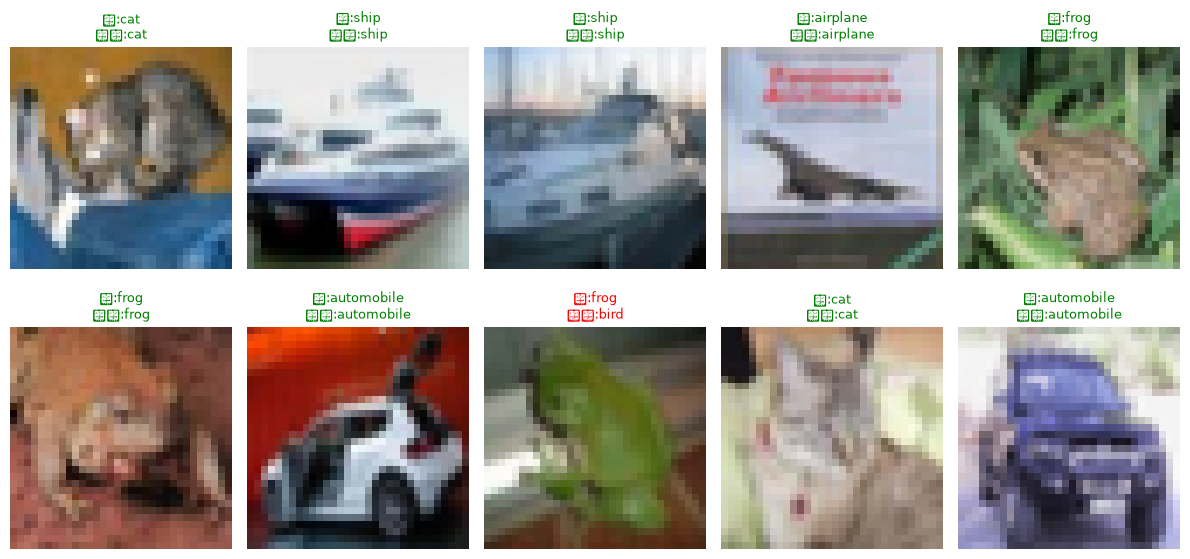

In [6]:
import matplotlib.pyplot as plt

model.eval()
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)
with torch.no_grad():
    preds = model(images).argmax(1)

classes = test_set.classes

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    img = images[i].cpu().clone()
    for c in range(3):                      # 反标准化，还原成可显示的像素
        img[c] = img[c] * STD[c] + MEAN[c]
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
    ok = classes[preds[i]] == classes[labels[i]]
    color = "green" if ok else "red"
    ax.set_title(f"真:{classes[labels[i]]}\n预测:{classes[preds[i]]}", color=color, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. 用自己的图片推理

把任意一张图（比如项目根目录的 `image.jpg`）缩放到 32×32 送进模型，看它判断成什么。注意：CIFAR-10 只有 10 类，你给的图如果不是这 10 类之一，模型也只能在这 10 类里「硬选」，这是正常现象。

In [7]:
from PIL import Image
from torchvision import transforms

model.eval()
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

image_path = "../image.jpg"   # 改成你自己的图片路径
image = Image.open(image_path).convert("RGB")
x = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    probs = torch.softmax(model(x), dim=1)
    top3 = probs.topk(3)

print("预测:", image_path)
for rank, (p, idx) in enumerate(zip(top3.values[0], top3.indices[0]), start=1):
    print(f"  {rank}. {classes[idx]:<10s}  {p.item():.4f}")

预测: ../image.jpg
  1. horse       0.6472
  2. airplane    0.1202
  3. cat         0.0952


## 下一步可以尝试

1. **改超参数**：换 `EPOCHS`、`lr`、`batch_size`，看准确率怎么变。
2. **换网络**：把卷积层数/通道数改大或改小，观察参数量与效果的关系。
3. **画训练曲线**：把每个 epoch 的 loss/acc 存下来画图，直观看到「过拟合」长什么样。
4. **迁移到自己的数据**：把 `datasets.CIFAR10` 换成 `ImageFolder` 指向你自己的图片文件夹，就能训练你自己的分类器。